# Dataset σαρκασμού: περιγραφή και CSV

Το notebook φτιάχνει τα δεδομένα του project, τα περιγράφει και τα γράφει σε ένα CSV (μία γραμμή = μία πρόταση).

**Πώς φτιάχνονται οι προτάσεις.** Για κάθε ζεύγος καταστάσεων (ευχάριστη / δυσάρεστη) και κάθε θετική φράση φτιάχνουμε μια τριάδα:

| | κατάσταση | φράση | σαρκασμός |
|---|---|---|---|
| **P** | ευχάριστη | θετική | 0 |
| **S** | δυσάρεστη | θετική | **1** |
| **N** | δυσάρεστη | αρνητική | 0 |

Η S διαφέρει από την P μόνο στην κατάσταση και από την N μόνο στη φράση.
Κάθε θετική φράση έχει τις «αντίθετές» της (π.χ. *This made my day.* → *This ruined my day.*) ώστε η N να μοιάζει όσο γίνεται με την S.

**Split.** Οι τριάδες με τη θετική φράση *"Great, just what I needed."* (και τις 2 αρνητικές της) είναι `heldout`:


## 1. Ρυθμίσεις και υλικό

In [ ]:
import html
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, display
from transformers import AutoTokenizer

TOKENIZER_NAME = "Qwen/Qwen2.5-7B-Instruct"   # ίδιος tokenizer με το 3B
CSV_PATH = "sarcasm_dataset.csv"

PAIRS = [  # (ευχάριστη, δυσάρεστη)
    ("relaxing on the beach", "waiting in the rain"), ("eating fresh pizza", "eating burnt toast"),
    ("getting a day off", "working on a Sunday"), ("winning the game", "losing my wallet"),
    ("sleeping in late", "waking up at 5am"), ("a quiet evening at home", "a three-hour meeting"),
    ("finding free parking", "getting a parking ticket"), ("a warm shower", "a cold shower in winter"),
    ("getting good news", "getting more homework"), ("a fast internet connection", "a slow internet connection"),
    ("my train arriving early", "my train being late again"), ("a sunny weekend", "a rainy weekend"),
    ("passing the exam", "failing the exam"), ("hot coffee in the morning", "cold coffee in the morning"),
    ("a clean kitchen", "a dirty kitchen"), ("friendly neighbors", "noisy neighbors"),
    ("a short queue", "a two-hour queue"), ("getting a gift", "getting a huge bill"),
    ("a free upgrade", "a cancelled flight"), ("my phone working", "my phone breaking"),
    ("a delicious dinner", "a burnt dinner"), ("a relaxing massage", "a painful dentist appointment"),
    ("finding my lost keys", "locking myself out"), ("a free concert", "a power outage"),
    ("my team winning", "my team losing again"), ("getting a raise", "getting fired"),
    ("a fresh haircut", "a terrible haircut"), ("a warm blanket", "a broken heater"),
    ("a peaceful walk", "stepping in a deep puddle"), ("a fast checkout", "a broken card machine"),
    ("a clean car", "a flat tire"), ("a long nap", "a sleepless night"),
    ("a great book", "a boring lecture"), ("fresh bread", "moldy bread"),
    ("my package arriving early", "my package getting lost"), ("a free lunch", "food poisoning"),
    ("a fun weekend trip", "a weekend of chores"), ("a cozy evening by the fire", "a leaking roof"),
    ("a sunny morning", "a rainy morning"), ("a good grade", "a bad grade"),
    ("a hot meal", "a cold meal"), ("a quiet night", "a loud night"),
    ("good weather", "bad weather"), ("a happy dog", "a sick dog"),
    ("an early train", "a late train"), ("a clean desk", "a messy desk"),
]

# θετική φράση -> οι αρνητικές «αντίθετές» της (σειρά προτίμησης)
FRAME_MAP = {
    "Wow, I just love that.":      ["Wow, I just hate that.", "Ugh, I just hate that."],
    "Great, just what I needed.":  ["Great, that ruined everything.", "That really ruined my day."],
    "This made my day.":           ["This ruined my day."],
    "Honestly, it was wonderful.": ["Honestly, it was awful.", "Honestly, it was terrible."],
    "I'm so lucky.":               ["I'm so unlucky.", "I'm so annoyed."],
}
HELDOUT_POS_FRAMES = ["Great, just what I needed."]

CONTEXT = "Today was all about {s}. {f}"
QUESTION = 'Someone said: "{u}"\nIs this person being sarcastic? Answer with Yes or No.'

tok = AutoTokenizer.from_pretrained(TOKENIZER_NAME)
print(f"{len(PAIRS)} ζεύγη καταστάσεων, {len(FRAME_MAP)} θετικές φράσεις, "
      f"{sum(len(v) for v in FRAME_MAP.values())} αρνητικές φράσεις")

config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

46 ζεύγη καταστάσεων, 5 θετικές φράσεις, 9 αρνητικές φράσεις


## 2. Κατασκευή των προτάσεων

`token_matched_PS` / `token_matched_SN`: αν οι δύο προτάσεις έχουν **ίδιο αριθμό tokens** και διαφέρουν **μόνο** στο κομμάτι που αλλάζει.
Μόνο αυτές οι τριάδες μπορούν να μπουν στο patching θέση προς θέση.

In [ ]:
def chat_ids(s, f):
    """Ολόκληρο το prompt με chat template -> token ids + θέσεις κατάστασης / φράσης."""
    u = CONTEXT.format(s=s, f=f)
    q = QUESTION.format(u=u)
    text = tok.apply_chat_template([{"role": "user", "content": q}], tokenize=False, add_generation_prompt=True)
    enc = tok(text, add_special_tokens=False, return_offsets_mapping=True)
    ids, offs = enc["input_ids"], enc["offset_mapping"]
    u0 = text.index(u)
    s0 = u0 + u.index(s); s1 = s0 + len(s)
    f0 = u0 + u.index(f); f1 = f0 + len(f)
    toks = lambda a, b: {i for i, (x, y) in enumerate(offs) if y > a and x < b}
    return ids, {"situation": toks(s0, s1), "frame": toks(f0, f1)}


def aligned(a, b, allowed):
    """Ίδιο μήκος και διαφορές μόνο στις επιτρεπτές θέσεις."""
    return len(a) == len(b) and all(i in allowed for i, (x, y) in enumerate(zip(a, b)) if x != y)


rows, triple_id = [], 0
for pair_id, (good, bad) in enumerate(PAIRS):
    for pf, neg_options in FRAME_MAP.items():
        S, regS = chat_ids(bad, pf)
        P, _ = chat_ids(good, pf)
        ps = aligned(S, P, regS["situation"])

        # αρνητική φράση: η πρώτη που ταιριάζει σε tokens με την S, αλλιώς εναλλάξ
        nf, sn = neg_options[pair_id % len(neg_options)], False
        for cand in neg_options:
            if aligned(S, chat_ids(bad, cand)[0], regS["frame"]):
                nf, sn = cand, True
                break
        N, _ = chat_ids(bad, nf)

        split = "heldout" if pf in HELDOUT_POS_FRAMES else "discovery"
        for cond, sit, sit_type, fr, fr_type, ids in [
            ("P", good, "pleasant",   pf, "positive", P),
            ("S", bad,  "unpleasant", pf, "positive", S),
            ("N", bad,  "unpleasant", nf, "negative", N),
        ]:
            text = CONTEXT.format(s=sit, f=fr)
            rows.append(dict(
                triple_id=triple_id, pair_id=pair_id, condition=cond, text=text,
                sarcastic=int(cond == "S"), situation=sit, situation_type=sit_type,
                frame=fr, frame_type=fr_type, positive_frame=pf,
                prompt=QUESTION.format(u=text), n_tokens=len(ids),
                token_matched_PS=ps, token_matched_SN=sn, split=split))
        triple_id += 1

df = pd.DataFrame(rows)
df.insert(0, "id", range(len(df)))
df.to_csv(CSV_PATH, index=False)
print(f"Γράφτηκε {CSV_PATH}: {len(df)} προτάσεις, {df.triple_id.nunique()} τριάδες")
df.head(6)

Γράφτηκε sarcasm_dataset.csv: 690 προτάσεις, 230 τριάδες


,id,triple_id,pair_id,condition,text,sarcastic,situation,situation_type,frame,frame_type,positive_frame,prompt,n_tokens,token_matched_PS,token_matched_SN,split
0,0,0,0,P,Today was all about relaxing on the beach. Wow...,0,relaxing on the beach,pleasant,"Wow, I just love that.",positive,"Wow, I just love that.","Someone said: ""Today was all about relaxing on...",62,True,True,discovery
1,1,0,0,S,"Today was all about waiting in the rain. Wow, ...",1,waiting in the rain,unpleasant,"Wow, I just love that.",positive,"Wow, I just love that.","Someone said: ""Today was all about waiting in ...",62,True,True,discovery
2,2,0,0,N,"Today was all about waiting in the rain. Wow, ...",0,waiting in the rain,unpleasant,"Wow, I just hate that.",negative,"Wow, I just love that.","Someone said: ""Today was all about waiting in ...",62,True,True,discovery
3,3,1,0,P,Today was all about relaxing on the beach. Gre...,0,relaxing on the beach,pleasant,"Great, just what I needed.",positive,"Great, just what I needed.","Someone said: ""Today was all about relaxing on...",62,True,False,heldout
4,4,1,0,S,Today was all about waiting in the rain. Great...,1,waiting in the rain,unpleasant,"Great, just what I needed.",positive,"Great, just what I needed.","Someone said: ""Today was all about waiting in ...",62,True,False,heldout
5,5,1,0,N,Today was all about waiting in the rain. Great...,0,waiting in the rain,unpleasant,"Great, that ruined everything.",negative,"Great, just what I needed.","Someone said: ""Today was all about waiting in ...",61,True,False,heldout


## 3. Περιγραφή: πλήθη

In [ ]:
print("Προτάσεις ανά condition και split")
display(pd.crosstab(df.condition, df.split, margins=True, margins_name="σύνολο"))

print("\nΣαρκαστικές (1) / μη σαρκαστικές (0)")
display(df.sarcastic.value_counts().rename_axis("sarcastic").to_frame("προτάσεις"))

t = df.drop_duplicates("triple_id")
usable = pd.DataFrame({
    "τριάδες": t.groupby("split").size(),
    "ταιριάζουν P-S": t.groupby("split").token_matched_PS.sum(),
    "ταιριάζουν S-N": t.groupby("split").token_matched_SN.sum(),
    "ταιριάζουν και τα δύο": t.groupby("split").apply(lambda g: (g.token_matched_PS & g.token_matched_SN).sum()),
})
print("\nΤριάδες που μπορούν να μπουν στο patching")
display(usable)

print("\nΜήκος σε tokens (ολόκληρο το prompt)")
display(df.groupby("condition").n_tokens.describe()[["mean", "min", "max"]].round(1))

Προτάσεις ανά condition και split


split,discovery,heldout,σύνολο
condition,,,
N,184,46,230
P,184,46,230
S,184,46,230
σύνολο,552,138,690



Σαρκαστικές (1) / μη σαρκαστικές (0)


,προτάσεις
sarcastic,
0,460
1,230



Τριάδες που μπορούν να μπουν στο patching


/tmp/ipykernel_1714/1114982157.py:12: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  "ταιριάζουν και τα δύο": t.groupby("split").apply(lambda g: (g.token_matched_PS & g.token_matched_SN).sum()),


,τριάδες,ταιριάζουν P-S,ταιριάζουν S-N,ταιριάζουν και τα δύο
split,,,,
discovery,184,116,184,116
heldout,46,29,0,0



Μήκος σε tokens (ολόκληρο το prompt)


,mean,min,max
condition,,,
N,60.3,58.0,64.0
P,60.2,58.0,64.0
S,60.5,58.0,64.0


## 4. Παραδείγματα τριάδων (με χρώμα ό,τι αλλάζει)

In [ ]:
def show_triples(n=6, seed=0):
    ids = df.drop_duplicates("triple_id").sample(n, random_state=seed).triple_id
    colors = {"P": "#e8f5e9", "S": "#fff3e0", "N": "#e3f2fd"}
    out = ["<table style='border-collapse:collapse;font-size:13px'>"
           "<tr><th>τριάδα</th><th>cond</th><th style='text-align:left'>πρόταση</th><th>σαρκασμός</th>"
           "<th>tokens</th><th>split</th></tr>"]
    for tid in ids:
        g = df[df.triple_id == tid].set_index("condition")
        for c in "PSN":
            r = g.loc[c]
            sit = html.escape(r.situation)
            fr = html.escape(r.frame)
            if c == "P":
                sit = f"<b style='color:#2e7d32'>{sit}</b>"
            if c == "N":
                fr = f"<b style='color:#1565c0'>{fr}</b>"
            if c == "S":
                sit, fr = f"<b style='color:#c62828'>{sit}</b>", f"<b style='color:#c62828'>{fr}</b>"
            txt = html.escape(CONTEXT).replace("{s}", sit).replace("{f}", fr)
            out.append(f"<tr style='background:{colors[c]}'><td>{tid}</td><td><b>{c}</b></td>"
                       f"<td style='text-align:left'>{txt}</td><td>{'✔' if r.sarcastic else ''}</td>"
                       f"<td>{r.n_tokens}</td><td>{r.split}</td></tr>")
    out.append("</table>")
    display(HTML("".join(out)))

show_triples()

τριάδα,cond,πρόταση,σαρκασμός,tokens,split
139,P,Today was all about a warm blanket. I'm so lucky.,,59,discovery
139,S,Today was all about a broken heater. I'm so lucky.,✔,59,discovery
139,N,Today was all about a broken heater. I'm so unlucky.,,59,discovery
201,P,"Today was all about a hot meal. Great, just what I needed.",,61,heldout
201,S,"Today was all about a cold meal. Great, just what I needed.",✔,61,heldout
201,N,"Today was all about a cold meal. Great, that ruined everything.",,60,heldout
122,P,Today was all about my team winning. This made my day.,,59,discovery
122,S,Today was all about my team losing again. This made my day.,✔,60,discovery
122,N,Today was all about my team losing again. This ruined my day.,,60,discovery
186,P,"Today was all about a cozy evening by the fire. Great, just what I needed.",,64,heldout


## 5. Διαγράμματα

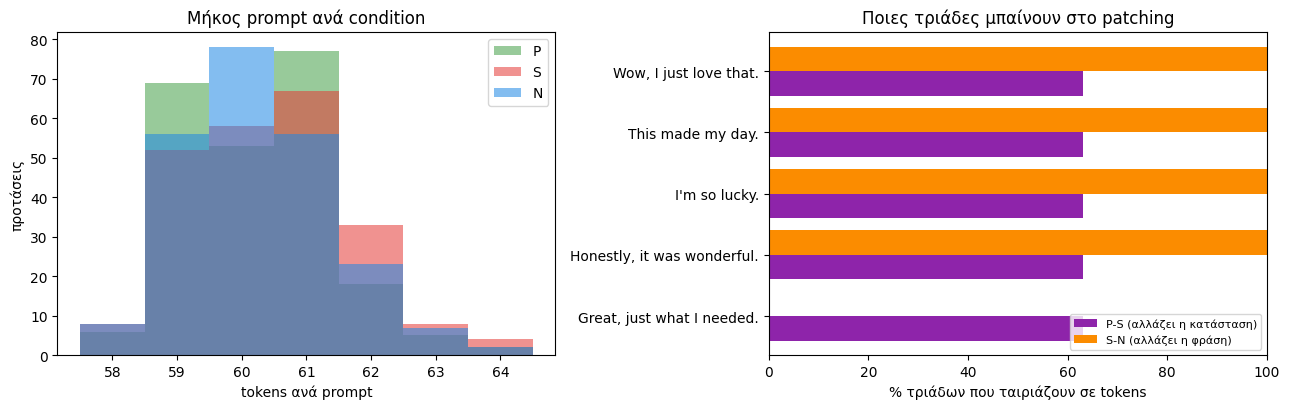

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

ax = axes[0]
bins = np.arange(df.n_tokens.min() - 0.5, df.n_tokens.max() + 1.5)
for c, col in zip("PSN", ["#43a047", "#e53935", "#1e88e5"]):
    ax.hist(df[df.condition == c].n_tokens, bins=bins, alpha=0.55, label=c, color=col)
ax.set_xlabel("tokens ανά prompt"); ax.set_ylabel("προτάσεις"); ax.legend()
ax.set_title("Μήκος prompt ανά condition")

ax = axes[1]
rate = t.groupby("positive_frame")[["token_matched_PS", "token_matched_SN"]].mean() * 100
y = np.arange(len(rate))
ax.barh(y - 0.2, rate.token_matched_PS, 0.4, label="P-S (αλλάζει η κατάσταση)", color="#8e24aa")
ax.barh(y + 0.2, rate.token_matched_SN, 0.4, label="S-N (αλλάζει η φράση)", color="#fb8c00")
ax.set_yticks(y); ax.set_yticklabels(rate.index); ax.set_xlim(0, 100)
ax.set_xlabel("% τριάδων που ταιριάζουν σε tokens"); ax.legend(loc="lower right", fontsize=8)
ax.set_title("Ποιες τριάδες μπαίνουν στο patching")
plt.tight_layout(); plt.show()

## 6. Γιατί κάποιες τριάδες δεν ταιριάζουν

Η ευχάριστη και η δυσάρεστη κατάσταση σπάνε σε διαφορετικό αριθμό tokens. Παραδείγματα:

In [ ]:
def pieces(s):
    return [tok.decode([i]) for i in tok.encode(" " + s, add_special_tokens=False)]

bad_pairs = t[~t.token_matched_PS].drop_duplicates("pair_id").head(6)
for _, r in bad_pairs.iterrows():
    good, bad = PAIRS[r.pair_id]
    print(f"  {good!r:30s} {len(pieces(good))} tokens  vs  {bad!r:30s} {len(pieces(bad))} tokens")
print(f"\nΖεύγη καταστάσεων που ταιριάζουν: {t.drop_duplicates('pair_id').token_matched_PS.sum()} από {len(PAIRS)}")

  'sleeping in late'             3 tokens  vs  'waking up at 5am'             6 tokens
  'a quiet evening at home'      5 tokens  vs  'a three-hour meeting'         4 tokens
  'finding free parking'         3 tokens  vs  'getting a parking ticket'     4 tokens
  'a warm shower'                3 tokens  vs  'a cold shower in winter'      5 tokens
  'my train arriving early'      4 tokens  vs  'my train being late again'    5 tokens
  'a short queue'                3 tokens  vs  'a two-hour queue'             4 tokens

Ζεύγη καταστάσεων που ταιριάζουν: 29 από 46


## 7. Κατέβασμα του CSV

In [ ]:
try:
    from google.colab import files
    files.download(CSV_PATH)
except ImportError:
    print("Εκτός Colab: το αρχείο είναι στο", CSV_PATH)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>